# 04 — CNN-LSTM Spatio-Temporal Water Quality Forecasting & Residual Anomaly Detection

**Project:** `miniproject2026` — Spatio-Temporal Satellite Water Contamination Analysis & Illegal Dumping Detection Engine  
**Stage:** Day 3 — Phases B–F (Colab-ready & locally reproducible)  

### Key Verified Findings from Phase A Data Inspection
1. **Verified NPZ Patch Shape:** All four lakes (`bellandur`, `hussain_sagar`, `yamuna_okhla`, `sukhna`) store `(32, 9, 64, 64)` `float32` tensors with channel order `['B02', 'B03', 'B04', 'B05', 'B06', 'B8A', 'NDCI', 'NDTI', 'water_mask']` (zero NaNs/Infs). Rather than cropping/dropping channels to force `(4, 8, 32, 32)`, `WaterCNNLSTM` is adapted directly to `(B, 4, 9, 64, 64)`.
2. **Target-Label Strategy (Case 2 — Hybrid Index + Teacher-Student Proxy Experiment):**
   - `NDWI_med`, `NDCI_med`, `NDTI_med`: direct Sentinel-2 L2A spectral index scene medians (`unitless`).
   - `Chla` (`pred_chla_proxy`, mg/m³) & `TSS` (`pred_tss_proxy`, mg/L): **proxy labels generated by Day 2 GLORIA Random Forest models**, *not* laboratory-confirmed ground truth. All `Chla`/`TSS` results are explicitly reported as proxy-target evaluation metrics.
3. **Chronological Split (Leakage-Resistant):**
   - 32 chronological dates per lake → 28 sliding windows (`t-4..t-1 → t`) per lake = **112 sequences total**.
   - **Train (`t = 4..18`):** 15/lake = 60 sequences (only uses observations `0..18`).
   - **Validation (`t = 19..23`):** 5/lake = 20 sequences (strictly `< 24`, zero test leakage).
   - **Held-out Test (`t = 24..31`):** 8/lake = 32 sequences (aligned 1-to-1 with Day 2 `anomaly_benchmark.npz`).

## 1. Environment Setup

In [1]:
# Uncomment in Google Colab if dependencies are missing:
# !pip install -q torch numpy pandas scikit-learn matplotlib
# !pip install -q onnx onnxruntime onnxscript

import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from torch.utils.data import DataLoader, Dataset

RANDOM_SEED = 42

def set_seed(seed: int = RANDOM_SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (feasible for 112 sequences of shape 4x9x64x64).")

PyTorch: 2.15.0+cpu
CUDA available: False
Running on CPU (feasible for 112 sequences of shape 4x9x64x64).


In [2]:
# Locate repository root (local repo or mounted Google Drive in Colab)
CWD = Path.cwd().resolve()
if (CWD / "SPEC.md").exists():
    ROOT = CWD
elif (CWD.parent / "SPEC.md").exists():
    ROOT = CWD.parent
else:
    # Colab fallback: mount Drive or adjust path if uploaded manually
    try:
        from google.colab import drive  # type: ignore
        drive.mount("/content/drive")
        candidate = Path("/content/drive/MyDrive/miniproject")
        ROOT = candidate if (candidate / "SPEC.md").exists() else CWD
    except Exception:
        ROOT = CWD

assert (ROOT / "SPEC.md").exists(), f"Could not locate SPEC.md from {ROOT}. Please set ROOT to repository path."

DATA_DIR = ROOT / "data" / "processed"
PATCH_DIR = DATA_DIR / "sentinel_patches"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "docs" / "figures"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

OFFICIAL_LAKES = ["bellandur", "hussain_sagar", "yamuna_okhla", "sukhna"]
EXPECTED_CHANNELS = ["B02", "B03", "B04", "B05", "B06", "B8A", "NDCI", "NDTI", "water_mask"]
TARGET_COLS = ["NDWI_med", "NDCI_med", "NDTI_med", "pred_chla_proxy", "pred_tss_proxy"]
TARGET_NAMES = ["NDWI", "NDCI", "NDTI", "Chla", "TSS"]
LOG_TARGET_INDICES = [3, 4]  # log1p applied ONLY to Chla and TSS

print("Repository root:", ROOT)
print("Patch directory:", PATCH_DIR)

Repository root: C:\Users\somya\OneDrive\Desktop\miniproject
Patch directory: C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\sentinel_patches


## 2. Dataset Loading

In [3]:
required_files = [
    *[PATCH_DIR / f"{lake}.npz" for lake in OFFICIAL_LAKES],
    DATA_DIR / "sentinel_anomalies.csv",
    DATA_DIR / "anomaly_benchmark.csv",
    DATA_DIR / "anomaly_benchmark.npz",
    MODELS_DIR / "baseline_metrics.json",
]
for fpath in required_files:
    assert fpath.exists(), f"Missing required file: {fpath}"

anomalies_df = pd.read_csv(DATA_DIR / "sentinel_anomalies.csv")
anomalies_df["date_dt"] = pd.to_datetime(anomalies_df["date"])
anomalies_df = anomalies_df.sort_values(["lake_id", "date_dt"]).reset_index(drop=True)

bench_df = pd.read_csv(DATA_DIR / "anomaly_benchmark.csv")
bench_npz = np.load(DATA_DIR / "anomaly_benchmark.npz", allow_pickle=False)
with open(MODELS_DIR / "baseline_metrics.json", "r", encoding="utf-8") as f:
    baseline_metrics = json.load(f)

lake_npz_data = {}
for lake in OFFICIAL_LAKES:
    with np.load(PATCH_DIR / f"{lake}.npz", allow_pickle=False) as z:
        lake_npz_data[lake] = {
            "patches": z["patches"].astype(np.float32),
            "dates": [str(d) for d in z["dates"]],
            "bounds": z["bounds"].astype(np.float64),
            "channel_names": [str(c) for c in z["channel_names"]],
        }

print(f"Loaded sentinel_anomalies.csv: {anomalies_df.shape}")
print(f"Loaded anomaly_benchmark.csv: {bench_df.shape}")
print(f"Loaded {len(lake_npz_data)} NPZ files.")

Loaded sentinel_anomalies.csv: (128, 50)
Loaded anomaly_benchmark.csv: (64, 33)
Loaded 4 NPZ files.


## 3. Dataset Validation

In [4]:
validation_summary = []
for lake in OFFICIAL_LAKES:
    item = lake_npz_data[lake]
    patches = item["patches"]
    dates = item["dates"]
    channels = item["channel_names"]

    assert patches.shape == (32, 9, 64, 64), f"{lake}: unexpected shape {patches.shape}"
    assert channels == EXPECTED_CHANNELS, f"{lake}: channel mismatch {channels}"
    assert np.isfinite(patches).all(), f"{lake}: non-finite values found in NPZ patches"

    sub_df = anomalies_df[anomalies_df["lake_id"] == lake].sort_values("date_dt").reset_index(drop=True)
    assert len(sub_df) == 32, f"{lake}: expected 32 CSV rows, got {len(sub_df)}"
    assert dates == sub_df["date"].tolist(), f"{lake}: NPZ and CSV date mismatch"
    assert pd.to_datetime(dates).is_monotonic_increasing, f"{lake}: dates not chronological"
    assert not sub_df[TARGET_COLS].isna().any().any(), f"{lake}: NaN found in targets"

    wm = patches[:, channels.index("water_mask"), :, :]
    water_px = (wm > 0.5).sum(axis=(1, 2))
    diffs = np.diff(pd.to_datetime(dates)).astype("timedelta64[D]").astype(int)

    validation_summary.append({
        "lake_id": lake,
        "shape": str(patches.shape),
        "n_dates": len(dates),
        "date_start": dates[0],
        "date_end": dates[-1],
        "gap_days_min_med_max": f"{diffs.min()}/{int(np.median(diffs))}/{diffs.max()}",
        "water_px_min_med_max": f"{int(water_px.min())}/{int(np.median(water_px))}/{int(water_px.max())}",
    })

print("Dataset validation passed for all 4 lakes.")
pd.DataFrame(validation_summary)

Dataset validation passed for all 4 lakes.


,lake_id,shape,n_dates,date_start,date_end,gap_days_min_med_max,water_px_min_med_max
0,bellandur,"(32, 9, 64, 64)",32,2024-06-01,2026-11-23,3/10/185,30/124/233
1,hussain_sagar,"(32, 9, 64, 64)",32,2024-06-16,2026-11-18,5/20/157,814/900/931
2,yamuna_okhla,"(32, 9, 64, 64)",32,2024-06-02,2026-11-24,5/20/125,291/449/604
3,sukhna,"(32, 9, 64, 64)",32,2024-06-02,2026-11-24,2/22/95,471/550/569


## 4. Temporal Sequence Generation

For each lake independently (chronologically sorted), we build 4-frame input windows `patches[t-4 : t]` predicting the immediately following observation `t` (`t = 4..31`), producing `28` sequences per lake (`112` total). Sequences never cross lake boundaries. Inter-observation temporal gaps (2–185 days, including monsoon gaps) are recorded in metadata.

In [5]:
SEQ_LEN = 4

seq_X = []
seq_y_raw = []
seq_meta = []

for lake in OFFICIAL_LAKES:
    patches = lake_npz_data[lake]["patches"]
    sub_df = anomalies_df[anomalies_df["lake_id"] == lake].sort_values("date_dt").reset_index(drop=True)
    dates = sub_df["date"].tolist()
    date_dts = sub_df["date_dt"].tolist()

    for t in range(SEQ_LEN, len(sub_df)):
        x_win = patches[t - SEQ_LEN : t]  # (4, 9, 64, 64)
        y_vec = sub_df.loc[t, TARGET_COLS].to_numpy(dtype=np.float32)  # (5,)
        prev_vec = sub_df.loc[t - 1, TARGET_COLS].to_numpy(dtype=np.float32)  # persistence baseline
        win_dates = dates[t - SEQ_LEN : t + 1]
        win_dts = date_dts[t - SEQ_LEN : t + 1]
        gaps = [int((win_dts[i + 1] - win_dts[i]).days) for i in range(SEQ_LEN)]

        seq_X.append(x_win)
        seq_y_raw.append(y_vec)
        seq_meta.append({
            "lake_id": lake,
            "target_idx": t,
            "target_date": dates[t],
            "input_dates": win_dates[:-1],
            "target_gap_days": gaps[-1],
            "max_gap_days": max(gaps),
            "prev_obs_raw": prev_vec,
        })

X_all = np.stack(seq_X, axis=0)      # (112, 4, 9, 64, 64)
y_all_raw = np.stack(seq_y_raw, axis=0)  # (112, 5)
meta_df = pd.DataFrame(seq_meta)

assert X_all.shape == (112, 4, 9, 64, 64)
assert y_all_raw.shape == (112, 5)
print("Generated temporal sequences:", X_all.shape, "| Targets:", y_all_raw.shape)
print("Per-lake sequences:", meta_df["lake_id"].value_counts().to_dict())

Generated temporal sequences: (112, 4, 9, 64, 64) | Targets: (112, 5)
Per-lake sequences: {'bellandur': 28, 'hussain_sagar': 28, 'yamuna_okhla': 28, 'sukhna': 28}


## 5. Chronological Train / Validation / Test Splitting & Normalization

- **Train (`target_idx` 4..18):** 15 sequences/lake = **60 sequences** (inputs/targets strictly within observations `0..18`).
- **Validation (`target_idx` 19..23):** 5 sequences/lake = **20 sequences** (strictly before test start index `24`).
- **Held-out Test (`target_idx` 24..31):** 8 sequences/lake = **32 sequences** (exact match to Day 2 `anomaly_benchmark.npz` dates).

Normalization statistics (`x_mean`, `x_std` over spectral/index channels `0..7`, keeping binary `water_mask` channel `8` unscaled; `log1p` on `Chla`/`TSS` followed by `y_mean`, `y_std` over training targets) are fitted **strictly on the training split**.

In [6]:
train_mask = (meta_df["target_idx"] <= 18).to_numpy()
val_mask = ((meta_df["target_idx"] >= 19) & (meta_df["target_idx"] <= 23)).to_numpy()
test_mask = (meta_df["target_idx"] >= 24).to_numpy()

assert train_mask.sum() == 60 and val_mask.sum() == 20 and test_mask.sum() == 32
assert not (train_mask & val_mask).any() and not (val_mask & test_mask).any()

def transform_targets_forward(y_raw: np.ndarray) -> np.ndarray:
    y_t = y_raw.copy().astype(np.float32)
    for idx in LOG_TARGET_INDICES:
        y_t[:, idx] = np.log1p(np.maximum(y_t[:, idx], 0.0))
    return y_t

def inverse_targets(y_trans: np.ndarray) -> np.ndarray:
    y_out = y_trans.copy().astype(np.float32)
    for idx in LOG_TARGET_INDICES:
        y_out[:, idx] = np.maximum(0.0, np.expm1(y_out[:, idx]))
    return y_out

X_train_raw, y_train_raw = X_all[train_mask], y_all_raw[train_mask]
X_val_raw, y_val_raw = X_all[val_mask], y_all_raw[val_mask]
X_test_raw, y_test_raw = X_all[test_mask], y_all_raw[test_mask]

# Fit channel normalization on training split ONLY (channels 0..7; channel 8 water_mask stays in {0, 1})
x_mean = X_train_raw[:, :, :8, :, :].mean(axis=(0, 1, 3, 4), keepdims=True)  # (1, 1, 8, 1, 1)
x_std = X_train_raw[:, :, :8, :, :].std(axis=(0, 1, 3, 4), keepdims=True)
x_std = np.maximum(x_std, 1e-6)

def normalize_X(X: np.ndarray, mean_8: np.ndarray, std_8: np.ndarray) -> np.ndarray:
    X_norm = X.copy().astype(np.float32)
    X_norm[:, :, :8, :, :] = (X_norm[:, :, :8, :, :] - mean_8) / std_8
    return X_norm

X_train = normalize_X(X_train_raw, x_mean, x_std)
X_val = normalize_X(X_val_raw, x_mean, x_std)
X_test = normalize_X(X_test_raw, x_mean, x_std)

# Fit target standardization on training split ONLY (after log1p on Chla and TSS)
y_train_trans = transform_targets_forward(y_train_raw)
y_val_trans = transform_targets_forward(y_val_raw)
y_test_trans = transform_targets_forward(y_test_raw)

y_mean = y_train_trans.mean(axis=0, keepdims=True)  # (1, 5)
y_std = np.maximum(y_train_trans.std(axis=0, keepdims=True), 1e-6)

y_train_scaled = (y_train_trans - y_mean) / y_std
y_val_scaled = (y_val_trans - y_mean) / y_std
y_test_scaled = (y_test_trans - y_mean) / y_std

split_table = pd.DataFrame([
    {"split": "Train (t=4..18)", "total": int(train_mask.sum()), **{l: int((meta_df.loc[train_mask, "lake_id"] == l).sum()) for l in OFFICIAL_LAKES}},
    {"split": "Validation (t=19..23)", "total": int(val_mask.sum()), **{l: int((meta_df.loc[val_mask, "lake_id"] == l).sum()) for l in OFFICIAL_LAKES}},
    {"split": "Held-out Test (t=24..31)", "total": int(test_mask.sum()), **{l: int((meta_df.loc[test_mask, "lake_id"] == l).sum()) for l in OFFICIAL_LAKES}},
])
print("Split counts (per lake and overall):")
display(split_table)
print("Input channel means (train 0..7):", np.round(x_mean.ravel(), 5).tolist())
print("Input channel stds  (train 0..7):", np.round(x_std.ravel(), 5).tolist())

Split counts (per lake and overall):


,split,total,bellandur,hussain_sagar,yamuna_okhla,sukhna
0,Train (t=4..18),60,15,15,15,15
1,Validation (t=19..23),20,5,5,5,5
2,Held-out Test (t=24..31),32,8,8,8,8


Input channel means (train 0..7): [0.01092000026255846, 0.015629999339580536, 0.013150000013411045, 0.0207700002938509, 0.025200000032782555, 0.027079999446868896, 0.04585999995470047, -0.02085999958217144]
Input channel stds  (train 0..7): [0.026489999145269394, 0.03550000116229057, 0.03175000101327896, 0.04676000028848648, 0.06785000115633011, 0.08237999677658081, 0.11479000002145767, 0.06533999741077423]


## 6. Data Augmentation (Training Set Only)

Allowed spatial-only transformations (horizontal flip, vertical flip, 90°/180°/270° rotation) are applied **identically** to all 4 frames and all 9 channels (`B02..water_mask`) in a training sequence. Temporal order is never altered, and validation/test sequences remain completely unaugmented.

In [7]:
class WaterSequenceDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray, augment: bool = False):
        self.X = torch.from_numpy(X.astype(np.float32))
        self.y = torch.from_numpy(y.astype(np.float32))
        self.augment = augment

    def __len__(self) -> int:
        return len(self.X)

    def __getitem__(self, idx: int):
        x = self.X[idx].clone()  # (4, 9, 64, 64)
        y = self.y[idx]
        if self.augment:
            if random.random() < 0.5:
                x = torch.flip(x, dims=[-1])  # horizontal flip across all 4 frames & 9 channels
            if random.random() < 0.5:
                x = torch.flip(x, dims=[-2])  # vertical flip across all 4 frames & 9 channels
            k_rot = random.randint(0, 3)
            if k_rot > 0:
                x = torch.rot90(x, k=k_rot, dims=(-2, -1))
        return x, y

BATCH_SIZE = 8
train_ds = WaterSequenceDataset(X_train, y_train_scaled, augment=True)
val_ds = WaterSequenceDataset(X_val, y_val_scaled, augment=False)
test_ds = WaterSequenceDataset(X_test, y_test_scaled, augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# Verify augmentation preserves temporal order & water_mask alignment
sample_x, _ = train_ds[0]
assert sample_x.shape == (4, 9, 64, 64)
assert set(torch.unique(sample_x[:, 8, :, :]).tolist()).issubset({0.0, 1.0})
print(f"Datasets ready: train={len(train_ds)} (augmented), val={len(val_ds)}, test={len(test_ds)}")

Datasets ready: train=60 (augmented), val=20, test=32


## 7. CNN-LSTM Architecture (`WaterCNNLSTM`)

Adapted cleanly to verified `(B, 4, 9, 64, 64)` input with compact regularization (`BatchNorm2d`, `Dropout`) appropriate for `n_train = 60`:
- `(B, 4, 9, 64, 64)` → `(B×4, 9, 64, 64)`
- CNN Spatial Encoder → global spatial pooling + Linear projection → `(B×4, 32)`
- Restore sequence → `(B, 4, 32)`
- LSTM Temporal Encoder (`hidden_size=32`) → `(B, 4, 32)` → last step `(B, 32)`
- Dense Output Layer → `(B, 5)` predicting scaled `[NDWI, NDCI, NDTI, log1p(Chla), log1p(TSS)]`

In [8]:
class WaterCNNLSTM(nn.Module):
    """Spatio-temporal CNN-LSTM adapted to (B, 4, 9, 64, 64) Sentinel-2 patches."""

    def __init__(self, in_channels: int = 9, feat_dim: int = 32, hidden_dim: int = 32, out_dim: int = 5):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 64 -> 32
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 32 -> 16
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.spatial_proj = nn.Sequential(
            nn.Dropout(0.25),
            nn.Linear(32, feat_dim),
            nn.ReLU(inplace=True),
        )
        self.lstm = nn.LSTM(
            input_size=feat_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
        )
        self.head = nn.Sequential(
            nn.Dropout(0.20),
            nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, t, c, h, w = x.shape
        assert t == 4 and c == 9 and h == 64 and w == 64, f"Unexpected input shape {x.shape}"
        x_flat = x.reshape(b * t, c, h, w)
        fmap = self.cnn(x_flat)                  # (B*4, 32, 16, 16)
        pooled = fmap.mean(dim=(-2, -1))         # (B*4, 32) global average pool (ONNX-friendly)
        spatial_vec = self.spatial_proj(pooled)  # (B*4, 32)
        seq = spatial_vec.reshape(b, t, -1)      # (B, 4, 32)
        lstm_out, _ = self.lstm(seq)             # (B, 4, 32)
        last_hidden = lstm_out[:, -1, :]         # (B, 32)
        out = self.head(last_hidden)             # (B, 5)
        return out

set_seed(RANDOM_SEED)
model = WaterCNNLSTM(in_channels=9, feat_dim=32, hidden_dim=32, out_dim=5).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# Test forward pass with shape assertions
dummy = torch.randn(2, 4, 9, 64, 64, device=device)
with torch.no_grad():
    dummy_out = model(dummy)
assert dummy_out.shape == (2, 5), f"Expected (2, 5), got {dummy_out.shape}"
assert torch.isfinite(dummy_out).all()
print(f"WaterCNNLSTM verified | Trainable params: {n_params:,} | Output shape: {tuple(dummy_out.shape)}")

WaterCNNLSTM verified | Trainable params: 25,029 | Output shape: (2, 5)


## 8. Training (`SmoothL1Loss`, `AdamW`, Early Stopping on Validation Loss)

Epoch   1/120 | train_loss=0.4313 | val_loss=0.5644 | best=0.5644 (ep 1)


Epoch   2/120 | train_loss=0.4177 | val_loss=0.5568 | best=0.5568 (ep 2)


Epoch   3/120 | train_loss=0.4081 | val_loss=0.5504 | best=0.5504 (ep 3)


Epoch   5/120 | train_loss=0.3767 | val_loss=0.5450 | best=0.5450 (ep 5)


Epoch   6/120 | train_loss=0.3653 | val_loss=0.5311 | best=0.5311 (ep 6)


Epoch   8/120 | train_loss=0.3445 | val_loss=0.5263 | best=0.5263 (ep 8)


... (15 outputs left out)

Epoch  40/120 | train_loss=0.2558 | val_loss=0.4539 | best=0.4510 (ep 34)


Epoch  41/120 | train_loss=0.2277 | val_loss=0.4486 | best=0.4486 (ep 41)


Epoch  50/120 | train_loss=0.2049 | val_loss=0.4727 | best=0.4486 (ep 41)


Early stopping triggered at epoch 56 (best epoch: 41, best val loss: 0.4486)


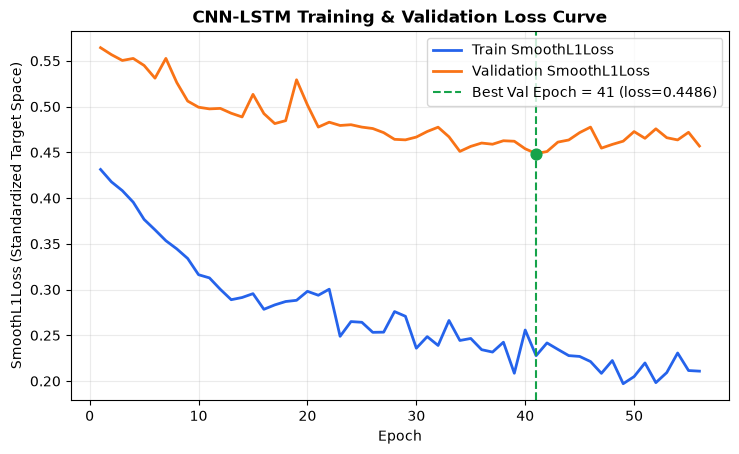

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\models\cnn_lstm_best.pt
Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\cnn_lstm_loss_curve.png


In [9]:
LR = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 120
PATIENCE = 15

criterion = nn.SmoothL1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

history = {"epoch": [], "train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_epoch = -1
epochs_no_improve = 0
ckpt_path = MODELS_DIR / "cnn_lstm_best.pt"

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item() * len(xb))
    train_loss = float(sum(train_losses) / len(train_ds))

    model.eval()
    val_losses = []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            loss = criterion(pred, yb)
            val_losses.append(loss.item() * len(xb))
    val_loss = float(sum(val_losses) / len(val_ds))

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_no_improve = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "input_channels": EXPECTED_CHANNELS,
            "target_names": TARGET_NAMES,
            "target_columns": TARGET_COLS,
            "input_shape": [4, 9, 64, 64],
            "x_mean_8": x_mean,
            "x_std_8": x_std,
            "y_mean_5": y_mean,
            "y_std_5": y_std,
            "log_target_indices": LOG_TARGET_INDICES,
            "training_config": {
                "loss": "SmoothL1Loss",
                "optimizer": "AdamW",
                "lr": LR,
                "weight_decay": WEIGHT_DECAY,
                "max_epochs": MAX_EPOCHS,
                "patience": PATIENCE,
                "batch_size": BATCH_SIZE,
            },
            "random_seed": RANDOM_SEED,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
        }, ckpt_path)
    else:
        epochs_no_improve += 1

    if epoch == 1 or epoch % 10 == 0 or epochs_no_improve == 0:
        print(f"Epoch {epoch:3d}/{MAX_EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | best={best_val_loss:.4f} (ep {best_epoch})")

    if epochs_no_improve >= PATIENCE:
        print(f"Early stopping triggered at epoch {epoch} (best epoch: {best_epoch}, best val loss: {best_val_loss:.4f})")
        break

# Plot and save training curves
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(history["epoch"], history["train_loss"], label="Train SmoothL1Loss", color="#2563eb", lw=2.0)
ax.plot(history["epoch"], history["val_loss"], label="Validation SmoothL1Loss", color="#f97316", lw=2.0)
ax.axvline(best_epoch, color="#16a34a", linestyle="--", lw=1.5, label=f"Best Val Epoch = {best_epoch} (loss={best_val_loss:.4f})")
ax.scatter([best_epoch], [best_val_loss], color="#16a34a", s=60, zorder=5)
ax.set_title("CNN-LSTM Training & Validation Loss Curve", fontsize=12, fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("SmoothL1Loss (Standardized Target Space)")
ax.legend()
ax.grid(alpha=0.25)
loss_fig_path = FIG_DIR / "cnn_lstm_loss_curve.png"
fig.savefig(loss_fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", ckpt_path)
print("Saved:", loss_fig_path)

## 9. Evaluation on Held-Out Chronological Test Data (`n = 32`)

Reload `models/cnn_lstm_best.pt`, evaluate strictly on the 32 held-out test sequences (`t = 24..31`), invert scaling, and apply `np.expm1` clipped `>= 0` **only** to `Chla` and `TSS` (keeping `NDWI`, `NDCI`, `NDTI` on their original scale).

Held-out Chronological Test Metrics (n = 32; Chla & TSS are proxy-target metrics):


,target,label_type,unit,r2_orig,mae_orig,rmse_orig,r2_log,mae_log,rmse_log
0,NDWI,Sentinel-2 Index,unitless,0.0926,0.1187,0.1681,NaN,NaN,NaN
1,NDCI,Sentinel-2 Index,unitless,-0.1182,0.0714,0.1029,NaN,NaN,NaN
2,NDTI,Sentinel-2 Index,unitless,0.1312,0.0616,0.0806,NaN,NaN,NaN
3,Chla,Day 2 RF Proxy (Case 2),mg/m³ (RF proxy),0.3146,71.9151,107.4930,0.3596,0.5069,0.6558
4,TSS,Day 2 RF Proxy (Case 2),mg/L (RF proxy),-0.0692,50.2683,149.5109,-0.0460,0.5408,0.7604


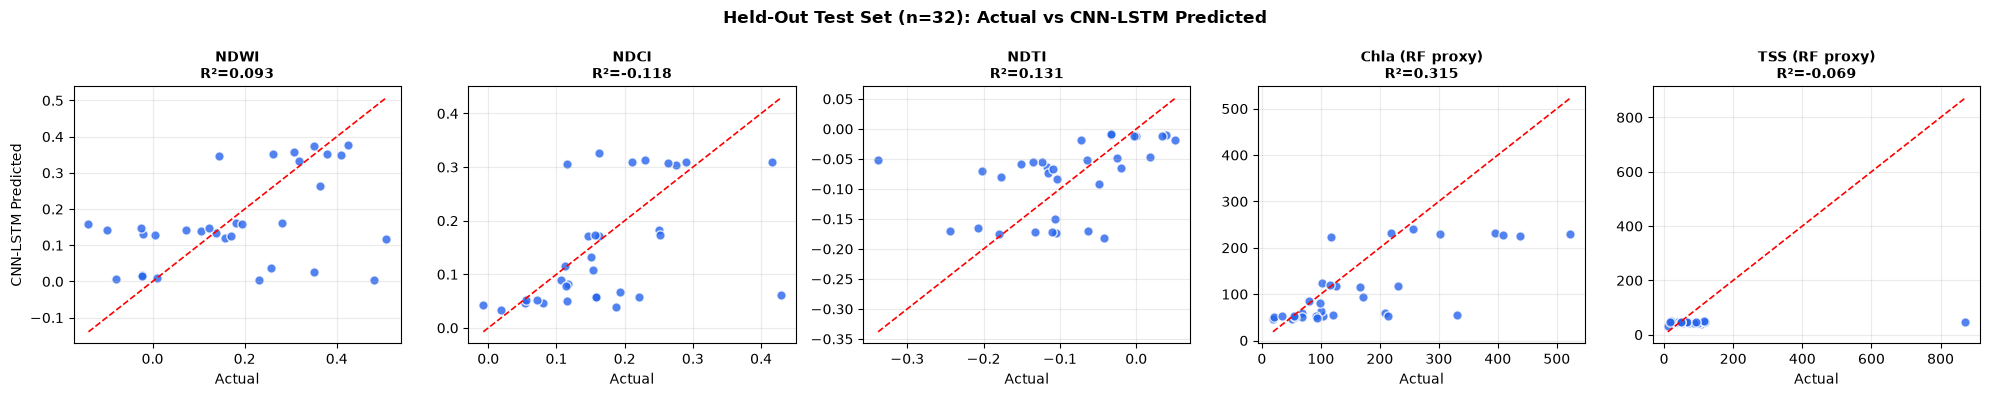

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\cnn_lstm_actual_vs_predicted.png


In [10]:
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
eval_model = WaterCNNLSTM(in_channels=9, feat_dim=32, hidden_dim=32, out_dim=5).to(device)
eval_model.load_state_dict(ckpt["model_state_dict"])
eval_model.eval()

def predict_with_model(m: nn.Module, X_norm: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    with torch.no_grad():
        xt = torch.from_numpy(X_norm.astype(np.float32)).to(device)
        pred_scaled = m(xt).cpu().numpy()
    pred_trans = pred_scaled * ckpt["y_std_5"] + ckpt["y_mean_5"]
    pred_raw = inverse_targets(pred_trans)
    return pred_scaled, pred_trans, pred_raw

_, pred_val_trans, pred_val_raw = predict_with_model(eval_model, X_val)
_, pred_test_trans, pred_test_raw = predict_with_model(eval_model, X_test)

def compute_regression_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
    }

test_metrics_rows = []
cnn_test_metrics = {}
for i, (tname, tcol) in enumerate(zip(TARGET_NAMES, TARGET_COLS)):
    orig_m = compute_regression_metrics(y_test_raw[:, i], pred_test_raw[:, i])
    is_proxy = tname in ("Chla", "TSS")
    unit = "mg/m³ (RF proxy)" if tname == "Chla" else ("mg/L (RF proxy)" if tname == "TSS" else "unitless")
    row = {
        "target": tname,
        "label_type": "Day 2 RF Proxy (Case 2)" if is_proxy else "Sentinel-2 Index",
        "unit": unit,
        "r2_orig": orig_m["r2"],
        "mae_orig": orig_m["mae"],
        "rmse_orig": orig_m["rmse"],
    }
    if is_proxy:
        log_m = compute_regression_metrics(y_test_trans[:, i], pred_test_trans[:, i])
        row["r2_log"] = log_m["r2"]
        row["mae_log"] = log_m["mae"]
        row["rmse_log"] = log_m["rmse"]
    else:
        row["r2_log"] = None
        row["mae_log"] = None
        row["rmse_log"] = None
    test_metrics_rows.append(row)
    cnn_test_metrics[tname] = row

test_metrics_df = pd.DataFrame(test_metrics_rows)
print("Held-out Chronological Test Metrics (n = 32; Chla & TSS are proxy-target metrics):")
display(test_metrics_df.round(4))

# Save Actual vs Predicted figure
fig, axes = plt.subplots(1, 5, figsize=(20, 4.0))
for i, (ax, tname) in enumerate(zip(axes, TARGET_NAMES)):
    yt = y_test_raw[:, i]
    yp = pred_test_raw[:, i]
    ax.scatter(yt, yp, alpha=0.8, color="#2563eb", edgecolors="white", s=45)
    lo = min(float(yt.min()), float(yp.min()))
    hi = max(float(yt.max()), float(yp.max()))
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.2)
    suffix = " (RF proxy)" if tname in ("Chla", "TSS") else ""
    ax.set_title(f"{tname}{suffix}\nR²={cnn_test_metrics[tname]['r2_orig']:.3f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Actual")
    if i == 0:
        ax.set_ylabel("CNN-LSTM Predicted")
    ax.grid(alpha=0.25)
fig.suptitle("Held-Out Test Set (n=32): Actual vs CNN-LSTM Predicted", fontsize=12, fontweight="bold")
fig.tight_layout()
avp_path = FIG_DIR / "cnn_lstm_actual_vs_predicted.png"
fig.savefig(avp_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", avp_path)

## 10. Baseline Comparison

1. **Direct comparison against saved Day 2 GLORIA metrics (`models/baseline_metrics.json`):** Day 2 `RandomForest` was evaluated on **GLORIA laboratory matchups** (`n_test = 908` Chla, `n_test = 904` TSS), whereas CNN-LSTM is evaluated on **32 held-out Sentinel-2 next-step forecasts** targeting Day 2 RF proxy outputs. Therefore, these two evaluations are **NOT directly equivalent** and are presented side-by-side with full disclosure.
2. **Same-32-observation temporal persistence baseline (`y_hat(t) = y(t-1)`):** Evaluated on the exact same 32 held-out Sentinel-2 dates (`t = 24..31`) to test whether CNN-LSTM learns temporal patterns beyond last-frame persistence.

Day 2 Baseline (GLORIA test) vs CNN-LSTM (Sentinel-2 proxy test) — NOT directly equivalent test sets:


,Target,Model,R2_orig,MAE_orig,RMSE_orig,R2_log,MAE_log,RMSE_log
0,Chla,"Day 2 baseline (RF on GLORIA lab, n=908)",0.3966,6.3446,38.5180,0.8754,0.2942,0.4238
1,Chla,"CNN-LSTM (Sentinel-2 RF proxy, n=32)",0.3146,71.9151,107.4930,0.3596,0.5069,0.6558
2,TSS,"Day 2 baseline (RF on GLORIA lab, n=904)",0.5625,13.5042,61.6927,0.4981,0.5877,0.7471
3,TSS,"CNN-LSTM (Sentinel-2 RF proxy, n=32)",-0.0692,50.2683,149.5109,-0.0460,0.5408,0.7604


Direct Same-Test-Set Comparison (n=32): Last-Observation Persistence vs CNN-LSTM:


,Target,Persist_R2,CNN_LSTM_R2,Persist_MAE,CNN_LSTM_MAE,Persist_RMSE,CNN_LSTM_RMSE
0,NDWI,-0.6723,0.0926,0.1767,0.1187,0.2282,0.1681
1,NDCI,-0.8009,-0.1182,0.0906,0.0714,0.1306,0.1029
2,NDTI,-0.5064,0.1312,0.0759,0.0616,0.1062,0.0806
3,Chla,0.2804,0.3146,77.6143,71.9151,110.1418,107.4930
4,TSS,-1.1144,-0.0692,82.4997,50.2683,210.2545,149.5109


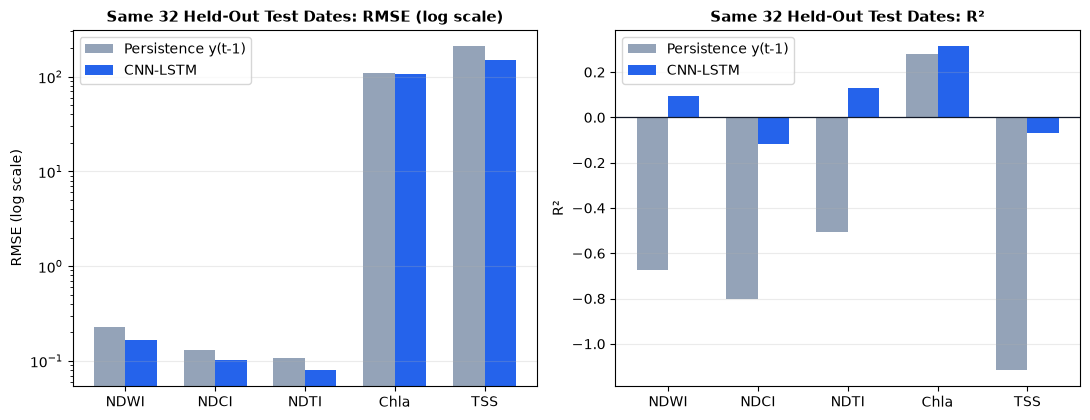

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\baseline_vs_cnn_lstm.png


In [11]:
day2_chla = baseline_metrics["selected_models"]["Chla"]["test"]
day2_tss = baseline_metrics["selected_models"]["TSS"]["test"]

# Day 2 vs CNN-LSTM comparison table (strictly from saved baseline_metrics.json)
comp_rows = [
    {
        "Target": "Chla",
        "Model": "Day 2 baseline (RF on GLORIA lab, n=908)",
        "R2_orig": day2_chla["r2_orig"],
        "MAE_orig": day2_chla["mae_orig"],
        "RMSE_orig": day2_chla["rmse_orig"],
        "R2_log": day2_chla["r2_log"],
        "MAE_log": day2_chla["mae_log"],
        "RMSE_log": day2_chla["rmse_log"],
    },
    {
        "Target": "Chla",
        "Model": "CNN-LSTM (Sentinel-2 RF proxy, n=32)",
        "R2_orig": cnn_test_metrics["Chla"]["r2_orig"],
        "MAE_orig": cnn_test_metrics["Chla"]["mae_orig"],
        "RMSE_orig": cnn_test_metrics["Chla"]["rmse_orig"],
        "R2_log": cnn_test_metrics["Chla"]["r2_log"],
        "MAE_log": cnn_test_metrics["Chla"]["mae_log"],
        "RMSE_log": cnn_test_metrics["Chla"]["rmse_log"],
    },
    {
        "Target": "TSS",
        "Model": "Day 2 baseline (RF on GLORIA lab, n=904)",
        "R2_orig": day2_tss["r2_orig"],
        "MAE_orig": day2_tss["mae_orig"],
        "RMSE_orig": day2_tss["rmse_orig"],
        "R2_log": day2_tss["r2_log"],
        "MAE_log": day2_tss["mae_log"],
        "RMSE_log": day2_tss["rmse_log"],
    },
    {
        "Target": "TSS",
        "Model": "CNN-LSTM (Sentinel-2 RF proxy, n=32)",
        "R2_orig": cnn_test_metrics["TSS"]["r2_orig"],
        "MAE_orig": cnn_test_metrics["TSS"]["mae_orig"],
        "RMSE_orig": cnn_test_metrics["TSS"]["rmse_orig"],
        "R2_log": cnn_test_metrics["TSS"]["r2_log"],
        "MAE_log": cnn_test_metrics["TSS"]["mae_log"],
        "RMSE_log": cnn_test_metrics["TSS"]["rmse_log"],
    },
]
comp_df = pd.DataFrame(comp_rows)
print("Day 2 Baseline (GLORIA test) vs CNN-LSTM (Sentinel-2 proxy test) — NOT directly equivalent test sets:")
display(comp_df.round(4))

# Same-32-scene temporal persistence baseline y_hat(t) = y(t-1)
persist_test_raw = np.stack(meta_df.loc[test_mask, "prev_obs_raw"].to_list(), axis=0)
persist_rows = []
for i, tname in enumerate(TARGET_NAMES):
    pm = compute_regression_metrics(y_test_raw[:, i], persist_test_raw[:, i])
    cm = cnn_test_metrics[tname]
    persist_rows.append({
        "Target": tname,
        "Persist_R2": pm["r2"],
        "CNN_LSTM_R2": cm["r2_orig"],
        "Persist_MAE": pm["mae"],
        "CNN_LSTM_MAE": cm["mae_orig"],
        "Persist_RMSE": pm["rmse"],
        "CNN_LSTM_RMSE": cm["rmse_orig"],
    })
persist_df = pd.DataFrame(persist_rows)
print("Direct Same-Test-Set Comparison (n=32): Last-Observation Persistence vs CNN-LSTM:")
display(persist_df.round(4))

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
x_pos = np.arange(len(TARGET_NAMES))
w = 0.35
axes[0].bar(x_pos - w / 2, persist_df["Persist_RMSE"], width=w, label="Persistence y(t-1)", color="#94a3b8")
axes[0].bar(x_pos + w / 2, persist_df["CNN_LSTM_RMSE"], width=w, label="CNN-LSTM", color="#2563eb")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(TARGET_NAMES)
axes[0].set_yscale("log")
axes[0].set_title("Same 32 Held-Out Test Dates: RMSE (log scale)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("RMSE (log scale)")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(x_pos - w / 2, persist_df["Persist_R2"], width=w, label="Persistence y(t-1)", color="#94a3b8")
axes[1].bar(x_pos + w / 2, persist_df["CNN_LSTM_R2"], width=w, label="CNN-LSTM", color="#2563eb")
axes[1].axhline(0.0, color="#111827", lw=0.9)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(TARGET_NAMES)
axes[1].set_title("Same 32 Held-Out Test Dates: R²", fontsize=11, fontweight="bold")
axes[1].set_ylabel("R²")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
bvc_path = FIG_DIR / "baseline_vs_cnn_lstm.png"
fig.savefig(bvc_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", bvc_path)

## 11. Residual Anomaly Detection & Exact Day 2 Benchmark Comparison

1. **Residual definition:** In model target space (`[NDWI_med, NDCI_med, NDTI_med, log1p(Chla), log1p(TSS)]`), `residual = actual - predicted`.
2. **Two-sided standardized anomaly score:** Using **validation residuals (`n = 20`) ONLY** to estimate per-target mean `mu_val` and std `std_val` (no test leakage), we define:
   `anomaly_score = max_k |residual_k - mu_val_k| / std_val_k`, and `is_anomaly = anomaly_score > 2.0`.
   *(Two-sided absolute Z-score detects both sudden upward contamination spikes and sudden downward drops, unlike Day 2's positive-only Rolling MAD).*
3. **Real Sentinel-2 scenes (`n = 32`):** Because no ground-truth real-world pollution labels exist, we report flagging counts & agreement with Day 2 Rolling MAD without claiming real-world Precision/Recall/F1.
4. **Exact Day 2 Semi-Synthetic Contamination Benchmark (`anomaly_benchmark.csv`, `n = 64`):** Evaluates the exact same 32 normal held-out scenes + 32 localized-plume injected copies (`t = 24..31`) over the 4 benchmark targets present in `anomaly_benchmark.csv` (`NDCI_med`, `NDTI_med`, `pred_chla_proxy`, `pred_tss_proxy`), comparing Precision, Recall, F1, and ROC-AUC against Day 2 Rolling MAD.

Real held-out scenes (n=32, NO real pollution labels): Day 2 Rolling MAD flagged 16/32 | CNN-LSTM residual (>2.0) flagged 6/32 | Agreement=18/32

Semi-Synthetic Contamination Benchmark Comparison (n=64, 32 normal + 32 injected plumes):


,Detector,Precision,Recall,F1,ROC-AUC,TP,FP,TN,FN
0,Day 2 Rolling MAD,0.6444,0.9062,0.7532,0.7964,29,16,16,3
1,CNN-LSTM residual detector,0.5000,0.1562,0.2381,0.4868,5,5,27,27


  Scenario algal_bloom         : MAD recall=0.812 | CNN-LSTM recall=0.250
  Scenario turbidity_sediment  : MAD recall=1.000 | CNN-LSTM recall=0.062


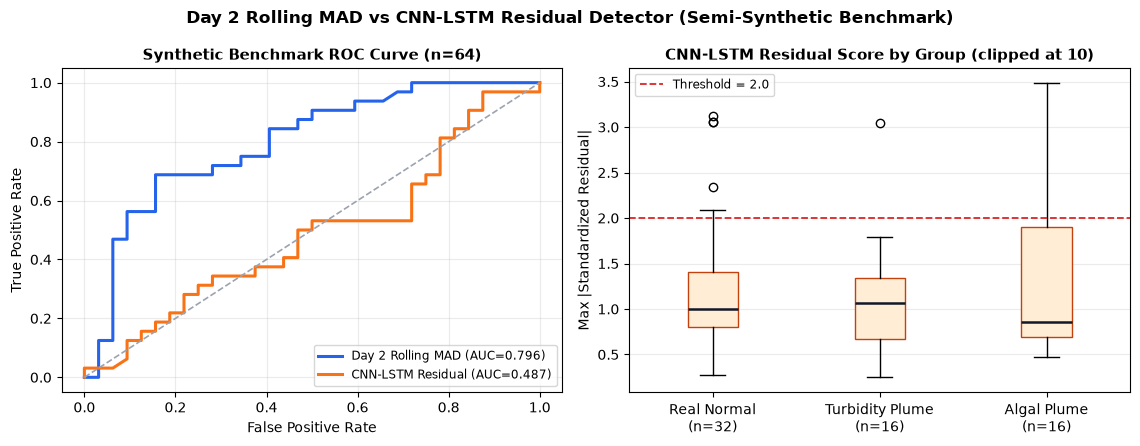

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\docs\figures\cnn_lstm_anomaly_comparison.png


In [12]:
# Fit residual mean & std strictly on VALIDATION set (n = 20) in transformed target space
val_res_trans = y_val_trans - pred_val_trans  # (20, 5)
res_mu_val = val_res_trans.mean(axis=0)
res_std_val = np.maximum(val_res_trans.std(axis=0), 1e-6)

# Real held-out test set (n = 32, all 5 targets)
test_res_trans = y_test_trans - pred_test_trans
test_z_abs = np.abs(test_res_trans - res_mu_val) / res_std_val
cnn_test_anom_score = test_z_abs.max(axis=1)
cnn_test_anom_flag = cnn_test_anom_score > 2.0

test_meta_df = meta_df[test_mask].copy().reset_index(drop=True)
real_test_rows = anomalies_df.merge(
    test_meta_df[["lake_id", "target_date"]].rename(columns={"target_date": "date"}),
    on=["lake_id", "date"],
    how="inner",
).sort_values(["lake_id", "date"]).reset_index(drop=True)
assert len(real_test_rows) == 32

mad_test_flag = real_test_rows["is_anomaly"].to_numpy(dtype=bool)
print(f"Real held-out scenes (n=32, NO real pollution labels): Day 2 Rolling MAD flagged {mad_test_flag.sum()}/32 | CNN-LSTM residual (>2.0) flagged {cnn_test_anom_flag.sum()}/32 | Agreement={int((mad_test_flag == cnn_test_anom_flag).sum())}/32")

# Exact Day 2 Semi-Synthetic Contamination Benchmark (n = 64)
# Map each (lake_id, date) in benchmark to its CNN-LSTM forecast from real preceding frames (t-4..t-1)
forecast_lookup = {}
for idx_row, mrow in test_meta_df.iterrows():
    forecast_lookup[(mrow["lake_id"], mrow["target_date"])] = pred_test_trans[idx_row]

# Benchmark CSV contains 4 of the 5 targets: NDCI_med (idx 1), NDTI_med (idx 2), pred_chla_proxy (idx 3), pred_tss_proxy (idx 4)
BENCH_TARGET_COLS = ["NDCI_med", "NDTI_med", "pred_chla_proxy", "pred_tss_proxy"]
BENCH_MODEL_INDICES = [1, 2, 3, 4]

cnn_bench_scores = []
for _, brow in bench_df.iterrows():
    key = (brow["lake_id"], brow["date"])
    pred_t = forecast_lookup[key][BENCH_MODEL_INDICES]
    actual_vals = np.array([
        float(brow["NDCI_med"]),
        float(brow["NDTI_med"]),
        float(np.log1p(max(0.0, brow["pred_chla_proxy"]))),
        float(np.log1p(max(0.0, brow["pred_tss_proxy"]))),
    ], dtype=np.float32)
    res_b = actual_vals - pred_t
    z_b = np.abs(res_b - res_mu_val[BENCH_MODEL_INDICES]) / res_std_val[BENCH_MODEL_INDICES]
    cnn_bench_scores.append(float(z_b.max()))

cnn_bench_scores = np.array(cnn_bench_scores, dtype=float)
cnn_bench_preds = (cnn_bench_scores > 2.0).astype(int)

y_true_b = bench_df["label"].to_numpy(dtype=int)
mad_bench_scores = bench_df["baseline_anomaly_score"].to_numpy(dtype=float)
mad_bench_preds = bench_df["pred_is_anomaly"].to_numpy(dtype=int)

def eval_detector(name: str, y_t: np.ndarray, y_p: np.ndarray, y_s: np.ndarray) -> dict:
    tn, fp, fn, tp = [int(v) for v in confusion_matrix(y_t, y_p).ravel()]
    return {
        "Detector": name,
        "Precision": float(precision_score(y_t, y_p, zero_division=0)),
        "Recall": float(recall_score(y_t, y_p, zero_division=0)),
        "F1": float(f1_score(y_t, y_p, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y_t, y_s)),
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
    }

mad_eval = eval_detector("Day 2 Rolling MAD", y_true_b, mad_bench_preds, mad_bench_scores)
cnn_eval = eval_detector("CNN-LSTM residual detector", y_true_b, cnn_bench_preds, cnn_bench_scores)
anom_comp_df = pd.DataFrame([mad_eval, cnn_eval])
print("\nSemi-Synthetic Contamination Benchmark Comparison (n=64, 32 normal + 32 injected plumes):")
display(anom_comp_df.round(4))

# By-scenario recall on injected cases
bench_df_eval = bench_df.copy()
bench_df_eval["cnn_score"] = cnn_bench_scores
bench_df_eval["cnn_pred"] = cnn_bench_preds
for scen, sub in bench_df_eval[bench_df_eval["label"] == 1].groupby("contamination_scenario"):
    print(f"  Scenario {scen:20s}: MAD recall={sub['pred_is_anomaly'].mean():.3f} | CNN-LSTM recall={sub['cnn_pred'].mean():.3f}")

# Plot ROC + score comparison
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
fpr_m, tpr_m, _ = roc_curve(y_true_b, mad_bench_scores)
fpr_c, tpr_c, _ = roc_curve(y_true_b, cnn_bench_scores)
axes[0].plot(fpr_m, tpr_m, lw=2.2, color="#2563eb", label=f"Day 2 Rolling MAD (AUC={mad_eval['ROC-AUC']:.3f})")
axes[0].plot(fpr_c, tpr_c, lw=2.2, color="#f97316", label=f"CNN-LSTM Residual (AUC={cnn_eval['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="#9ca3af", lw=1.2)
axes[0].set_title("Synthetic Benchmark ROC Curve (n=64)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(alpha=0.25)

axes[1].boxplot(
    [
        np.clip(cnn_bench_scores[y_true_b == 0], 0, 10),
        np.clip(cnn_bench_scores[bench_df["contamination_scenario"] == "turbidity_sediment"], 0, 10),
        np.clip(cnn_bench_scores[bench_df["contamination_scenario"] == "algal_bloom"], 0, 10),
    ],
    tick_labels=["Real Normal\n(n=32)", "Turbidity Plume\n(n=16)", "Algal Plume\n(n=16)"],
    patch_artist=True,
    boxprops=dict(facecolor="#ffedd5", color="#c2410c"),
    medianprops=dict(color="#111827", linewidth=1.8),
)
axes[1].axhline(2.0, color="#dc2626", linestyle="--", lw=1.3, label="Threshold = 2.0")
axes[1].set_title("CNN-LSTM Residual Score by Group (clipped at 10)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Max |Standardized Residual|")
axes[1].legend(loc="upper left", fontsize=8.5)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Day 2 Rolling MAD vs CNN-LSTM Residual Detector (Semi-Synthetic Benchmark)", fontsize=12, fontweight="bold")
fig.tight_layout()
anom_fig_path = FIG_DIR / "cnn_lstm_anomaly_comparison.png"
fig.savefig(anom_fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", anom_fig_path)

## 12. Model Export, Checkpoint Validation & Metrics Persistence

In [13]:
# 1. Reload checkpoint from disk and validate sample inference on a held-out test input
reloaded_ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
reloaded_model = WaterCNNLSTM(in_channels=9, feat_dim=32, hidden_dim=32, out_dim=5)
reloaded_model.load_state_dict(reloaded_ckpt["model_state_dict"])
reloaded_model.eval()

sample_raw = X_test_raw[:1]  # (1, 4, 9, 64, 64)
sample_norm = normalize_X(sample_raw, reloaded_ckpt["x_mean_8"], reloaded_ckpt["x_std_8"])
with torch.no_grad():
    sample_scaled = reloaded_model(torch.from_numpy(sample_norm)).numpy()
sample_trans = sample_scaled * reloaded_ckpt["y_std_5"] + reloaded_ckpt["y_mean_5"]
sample_pred = inverse_targets(sample_trans)

assert sample_pred.shape == (1, 5)
assert np.isfinite(sample_pred).all()
assert np.allclose(sample_pred, pred_test_raw[:1], atol=1e-5)
print("Checkpoint reload & reproducible inference PASSED | Sample output:", np.round(sample_pred[0], 4).tolist())

# 2. Optional ONNX export & ONNX Runtime verification
onnx_path = MODELS_DIR / "cnn_lstm_best.onnx"
onnx_status = {"exported": False, "verified_onnxruntime": False, "path": None, "error": None}
try:
    import onnx
    import onnxruntime as ort

    dummy_in = torch.from_numpy(sample_norm)
    torch.onnx.export(
        reloaded_model,
        dummy_in,
        str(onnx_path),
        input_names=["input_sequence"],
        output_names=["predictions"],
        dynamic_axes={"input_sequence": {0: "batch"}, "predictions": {0: "batch"}},
        opset_version=17,
        dynamo=False,
    )
    ort_sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
    ort_out = ort_sess.run(None, {"input_sequence": sample_norm})[0]
    max_diff = float(np.max(np.abs(ort_out - sample_scaled)))
    assert np.allclose(ort_out, sample_scaled, atol=1e-4), f"ORT mismatch max_diff={max_diff}"
    onnx_status = {"exported": True, "verified_onnxruntime": True, "path": "models/cnn_lstm_best.onnx", "max_abs_diff": max_diff}
    print(f"ONNX export & ONNX Runtime verification PASSED (max_abs_diff={max_diff:.2e})")
except Exception as exc:
    onnx_status["error"] = repr(exc)
    print("ONNX export note:", exc)

# 3. Save models/cnn_lstm_metrics.json (preserving models/baseline_metrics.json untouched)
cnn_metrics_payload = {
    "model_name": "WaterCNNLSTM",
    "checkpoint_path": "models/cnn_lstm_best.pt",
    "onnx_export": onnx_status,
    "dataset_info": {
        "npz_dir": "data/processed/sentinel_patches/",
        "csv_source": "data/processed/sentinel_anomalies.csv",
        "actual_input_shape": [4, 9, 64, 64],
        "channel_order": EXPECTED_CHANNELS,
        "target_order": TARGET_NAMES,
        "target_columns": TARGET_COLS,
        "label_sources": {
            "NDWI": "Sentinel-2 L2A scene median (unitless)",
            "NDCI": "Sentinel-2 L2A scene median (unitless)",
            "NDTI": "Sentinel-2 L2A scene median (unitless)",
            "Chla": "Day 2 Random Forest proxy estimate (mg/m^3, NOT ground truth)",
            "TSS": "Day 2 Random Forest proxy estimate (mg/L, NOT ground truth)",
        },
        "total_sequences": int(len(X_all)),
        "chronological_split": {
            "train": {"target_indices": "4..18", "count": int(train_mask.sum()), "per_lake": 15},
            "validation": {"target_indices": "19..23", "count": int(val_mask.sum()), "per_lake": 5},
            "test": {"target_indices": "24..31", "count": int(test_mask.sum()), "per_lake": 8},
        },
    },
    "training_configuration": {
        **reloaded_ckpt["training_config"],
        "random_seed": RANDOM_SEED,
        "best_epoch": int(best_epoch),
        "best_val_loss": float(best_val_loss),
        "final_train_loss": float(history["train_loss"][-1]),
        "final_val_loss": float(history["val_loss"][-1]),
        "trainable_parameters": int(n_params),
        "augmentation": "Train-only random horizontal/vertical flips and 90/180/270 rotations applied uniformly across 4 frames & 9 channels",
        "normalization": "Train-only channel standardization on channels 0..7 (water_mask kept in {0,1}); log1p on Chla & TSS then train-only target standardization",
    },
    "test_metrics": cnn_test_metrics,
    "persistence_baseline_same_32_test": persist_df.to_dict(orient="records"),
    "day2_gloria_baseline_reference": {
        "note": "Evaluated on GLORIA lab matchups (n=908 Chla, n=904 TSS) — NOT directly equivalent to Sentinel-2 n=32 proxy forecasts.",
        "Chla": day2_chla,
        "TSS": day2_tss,
    },
    "anomaly_comparison": {
        "method": "Two-sided max |residual - mu_val| / std_val > 2.0 (fitted on validation residuals n=20 ONLY)",
        "real_held_out_test_n32": {
            "day2_rolling_mad_flagged": int(mad_test_flag.sum()),
            "cnn_lstm_residual_flagged": int(cnn_test_anom_flag.sum()),
            "agreement_count": int((mad_test_flag == cnn_test_anom_flag).sum()),
            "note": "No real-world anomaly ground-truth labels exist; Precision/Recall/F1 cannot be claimed on real scenes.",
        },
        "synthetic_benchmark_n64": {
            "note": "Exact Day 2 anomaly_benchmark.csv (32 normal + 32 injected plumes on t=24..31), evaluated across the 4 shared benchmark targets (NDCI_med, NDTI_med, pred_chla_proxy, pred_tss_proxy).",
            "day2_rolling_mad": mad_eval,
            "cnn_lstm_residual": cnn_eval,
        },
    },
    "limitations": [
        "No laboratory-confirmed Chla/TSS measurements exist for the 4 Indian Sentinel-2 lakes; Chla and TSS targets are Day 2 RF proxy estimates (Case 2 teacher-student experiment).",
        "Small dataset size (112 total temporal sequences: 60 train, 20 val, 32 test) limits deep spatio-temporal generalization.",
        "Irregular inter-observation intervals (2 to 185 days across monsoon cloud gaps) violate fixed-step LSTM spacing assumptions.",
        "Actual NPZ patches are (9, 64, 64) with B8A (no B08/NDWI/B07 channel), rather than (8, 32, 32).",
        "Semi-synthetic benchmark evaluates localized simulated B04/B05 plumes only and does not prove real-world pollution detection accuracy.",
    ],
}

metrics_out_path = MODELS_DIR / "cnn_lstm_metrics.json"
with open(metrics_out_path, "w", encoding="utf-8") as f:
    json.dump(cnn_metrics_payload, f, indent=2)
print("Saved:", metrics_out_path)

Checkpoint reload & reproducible inference PASSED | Sample output: [0.14100000262260437, 0.08129999786615372, -0.06400000303983688, 59.740299224853516, 43.06480026245117]


C:\Users\somya\AppData\Local\Temp\ipykernel_24036\3058185278.py:27: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
C:\Users\somya\AppData\Local\Temp\ipykernel_24036\3330049555.py:37: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  assert t == 4 and c == 9 and h == 64 and w == 64, f"Unexpected input shape {x.shape}"
C:\Users\somya\OneDrive\Desktop\miniproject\.venv\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\

ONNX export & ONNX Runtime verification PASSED (max_abs_diff=1.19e-07)
Saved: C:\Users\somya\OneDrive\Desktop\miniproject\models\cnn_lstm_metrics.json


## 13. Phase F2–F4: ONNX FP32 Export, Parity Check & Dynamic INT8 Quantization

Using the verified trained checkpoint `models/cnn_lstm_best.pt` (`(B, 4, 9, 64, 64)` -> `(B, 5)`):
1. Export self-contained `models/cnn_lstm_fp32.onnx` (opset 18, `dynamo=True`, `external_data=False`, dynamic batch dimension) and validate with `onnx.checker` and ONNX Runtime.
2. Verify FP32 numerical parity against PyTorch FP32 across both the held-out test set (`n = 32`) and all sequences (`n = 112`).
3. Apply `quant_pre_process` + dynamic `QInt8` quantization (`models/cnn_lstm_int8.onnx`), inspect quantized vs FP32 operators, and validate inference + numerical drift.

In [9]:
import gc
import os
import platform
import time
import onnx
import onnxruntime as ort
from onnxruntime.quantization import QuantType, quantize_dynamic
from onnxruntime.quantization.shape_inference import quant_pre_process

# Load trained checkpoint & build evaluation model (no retraining)
ckpt_path = MODELS_DIR / "cnn_lstm_best.pt"
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
pt_model = WaterCNNLSTM(in_channels=9, feat_dim=32, hidden_dim=32, out_dim=5)
pt_model.load_state_dict(ckpt["model_state_dict"])
pt_model.eval()

X_all_norm = normalize_X(X_all, ckpt["x_mean_8"], ckpt["x_std_8"])
X_test_norm = X_all_norm[test_mask]

# 1. Export PyTorch -> ONNX FP32 (self-contained single file, dynamic batch axis)
fp32_onnx_path = MODELS_DIR / "cnn_lstm_fp32.onnx"
batch_dim = torch.export.Dim("batch", min=1, max=1024)
dummy_input = torch.from_numpy(X_test_norm[:2].copy())
torch.onnx.export(
    pt_model,
    (dummy_input,),
    str(fp32_onnx_path),
    input_names=["input_sequence"],
    output_names=["predictions"],
    dynamic_axes=None,
    dynamic_shapes={"x": {0: batch_dim}},
    opset_version=18,
    dynamo=True,
    external_data=False,
)
assert fp32_onnx_path.exists() and not fp32_onnx_path.with_suffix(".onnx.data").exists()

onnx_fp32_proto = onnx.load(str(fp32_onnx_path))
onnx.checker.check_model(onnx_fp32_proto)
print("ONNX FP32 graph validation passed:", fp32_onnx_path)

sess_fp32 = ort.InferenceSession(str(fp32_onnx_path), providers=["CPUExecutionProvider"])
for bs in [1, 8, 20, 32]:
    out_bs = sess_fp32.run(None, {"input_sequence": X_test_norm[:bs]})[0]
    assert out_bs.shape == (bs, 5) and np.isfinite(out_bs).all()

with torch.no_grad():
    pt_test_scaled = pt_model(torch.from_numpy(X_test_norm)).numpy()
    pt_all_scaled = pt_model(torch.from_numpy(X_all_norm)).numpy()

ort_fp32_test_scaled = sess_fp32.run(None, {"input_sequence": X_test_norm})[0]
ort_fp32_all_scaled = sess_fp32.run(None, {"input_sequence": X_all_norm})[0]

def compute_diff_stats(ref: np.ndarray, cand: np.ndarray) -> dict:
    diff = cand - ref
    abs_diff = np.abs(diff)
    rel_l2 = float(np.linalg.norm(diff) / max(float(np.linalg.norm(ref)), 1e-12))
    rel_mean = float(np.mean(abs_diff / np.maximum(np.abs(ref), 1e-8)))
    ref_raw = inverse_targets(ref * ckpt["y_std_5"] + ckpt["y_mean_5"])
    cand_raw = inverse_targets(cand * ckpt["y_std_5"] + ckpt["y_mean_5"])
    raw_abs = np.abs(cand_raw - ref_raw)
    per_target_raw = {
        tname: {
            "max_abs_diff": float(np.max(raw_abs[:, j])),
            "mean_abs_diff": float(np.mean(raw_abs[:, j])),
            "rmse_diff": float(np.sqrt(np.mean((cand_raw[:, j] - ref_raw[:, j]) ** 2))),
        }
        for j, tname in enumerate(TARGET_NAMES)
    }
    return {
        "all_finite": bool(np.isfinite(cand).all()),
        "shape": list(cand.shape),
        "scaled_space": {
            "max_abs_diff": float(np.max(abs_diff)),
            "mean_abs_diff": float(np.mean(abs_diff)),
            "rmse_diff": float(np.sqrt(np.mean(diff ** 2))),
            "relative_l2_diff": rel_l2,
            "relative_mean_diff": rel_mean,
        },
        "original_units": per_target_raw,
    }

fp32_diff_test = compute_diff_stats(pt_test_scaled, ort_fp32_test_scaled)
fp32_diff_all = compute_diff_stats(pt_all_scaled, ort_fp32_all_scaled)
print(f"FP32 vs PyTorch (n=32) | max_abs_diff={fp32_diff_test['scaled_space']['max_abs_diff']:.2e} | rmse={fp32_diff_test['scaled_space']['rmse_diff']:.2e}")

# 2. Dynamic INT8 quantization
prep_onnx_path = ROOT / "scratch" / "cnn_lstm_fp32_prep.onnx"
prep_onnx_path.parent.mkdir(parents=True, exist_ok=True)
quant_pre_process(str(fp32_onnx_path), str(prep_onnx_path))

int8_onnx_path = MODELS_DIR / "cnn_lstm_int8.onnx"
quantize_dynamic(
    model_input=str(prep_onnx_path),
    model_output=str(int8_onnx_path),
    weight_type=QuantType.QInt8,
)
onnx_int8_proto = onnx.load(str(int8_onnx_path))
onnx.checker.check_model(onnx_int8_proto)
print("ONNX INT8 graph validation passed:", int8_onnx_path)

fp32_ops = {}
for n in onnx_fp32_proto.graph.node:
    fp32_ops[n.op_type] = fp32_ops.get(n.op_type, 0) + 1

int8_ops = {}
for n in onnx_int8_proto.graph.node:
    int8_ops[n.op_type] = int8_ops.get(n.op_type, 0) + 1

print("FP32 ops:", fp32_ops)
print("INT8 ops:", int8_ops)

sess_int8 = ort.InferenceSession(str(int8_onnx_path), providers=["CPUExecutionProvider"])
for bs in [1, 8, 20, 32]:
    out_bs = sess_int8.run(None, {"input_sequence": X_test_norm[:bs]})[0]
    assert out_bs.shape == (bs, 5) and np.isfinite(out_bs).all()

ort_int8_test_scaled = sess_int8.run(None, {"input_sequence": X_test_norm})[0]
ort_int8_all_scaled = sess_int8.run(None, {"input_sequence": X_all_norm})[0]
int8_diff_test = compute_diff_stats(pt_test_scaled, ort_int8_test_scaled)
int8_diff_all = compute_diff_stats(pt_all_scaled, ort_int8_all_scaled)
print(f"INT8 vs PyTorch (n=32) | max_abs_diff={int8_diff_test['scaled_space']['max_abs_diff']:.4f} | Chla max_diff={int8_diff_test['original_units']['Chla']['max_abs_diff']:.4f} mg/m³")
print(f"INT8 vs PyTorch (n=112)| max_abs_diff={int8_diff_all['scaled_space']['max_abs_diff']:.4f} | Chla max_diff={int8_diff_all['original_units']['Chla']['max_abs_diff']:.4f} mg/m³")

[torch.onnx] Obtain model graph for `WaterCNNLSTM([...]` with `torch.export.export(..., strict=False)`...


C:\Users\somya\OneDrive\Desktop\miniproject\.venv\Lib\site-packages\torch\_dynamo\utils.py:4549: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  return node.target(*args, **kwargs)  # type: ignore[operator]


<eval_with_key>.1:6: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  _check_is_size = torch._check_is_size(item);  _check_is_size = None
<eval_with_key>.1:7: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  _check_is_size_1 = torch._check_is_size(item, max = 3);  _check_is_size_1 = None


<eval_with_key>.7:10: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  _check_is_size = torch._check_is_size(item);  _check_is_size = None
<eval_with_key>.7:11: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  _check_is_size_1 = torch._check_is_size(item, max = 3);  _check_is_size_1 = None
C:\Users\somya\PYTHON3.11\Lib\contextlib.py:144: UserWarning: The tensor attributes self.lstm._flat_weights[0], self.lstm._flat_weights[1], self.lstm._flat_weights[2], self.lstm._flat_weights[3] were assigned during export. Such attributes must be registered as buffers using the `register_buffer` API (https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_buffer).
  next(self.gen)


[torch.onnx] Obtain model graph for `WaterCNNLSTM([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


C:\Users\somya\OneDrive\Desktop\miniproject\.venv\Lib\site-packages\torch\_dynamo\utils.py:4549: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  return node.target(*args, **kwargs)  # type: ignore[operator]
<eval_with_key>.21:6: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  _check_is_size = torch._check_is_size(item);  _check_is_size = None
<eval_with_key>.21:7: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  _check_is_size_1 = torch._check_is_size(item, max = 3);  _check_is_size_1 = None
<eval_with_key>.27:6: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  _check_is_size = torch._check_is_size(item);  _check_is_size =

... (2 outputs left out)

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX FP32 graph validation passed: C:\Users\somya\OneDrive\Desktop\miniproject\models\cnn_lstm_fp32.onnx


FP32 vs PyTorch (n=32) | max_abs_diff=3.58e-07 | rmse=1.42e-07


ONNX INT8 graph validation passed: C:\Users\somya\OneDrive\Desktop\miniproject\models\cnn_lstm_int8.onnx
FP32 ops: {'Shape': 2, 'Reshape': 4, 'Conv': 3, 'Relu': 4, 'MaxPool': 2, 'ReduceMean': 1, 'Gemm': 2, 'Concat': 2, 'Expand': 1, 'Transpose': 3, 'Slice': 5, 'LSTM': 1, 'Mul': 1, 'Gather': 1}
INT8 ops: {'Reshape': 7, 'Shape': 2, 'Concat': 2, 'DynamicQuantizeLinear': 5, 'Expand': 1, 'Mul': 11, 'ConvInteger': 3, 'Slice': 5, 'Cast': 5, 'Add': 5, 'Relu': 4, 'MaxPool': 2, 'ReduceMean': 1, 'MatMulInteger': 2, 'Transpose': 2, 'DynamicQuantizeLSTM': 1, 'Gather': 2}


INT8 vs PyTorch (n=32) | max_abs_diff=0.0863 | Chla max_diff=3.8724 mg/m³
INT8 vs PyTorch (n=112)| max_abs_diff=0.6961 | Chla max_diff=28.9317 mg/m³


## 14. Phase F5: CPU Inference Benchmarking & Comparison Report

Fair CPU comparison across PyTorch FP32, ONNX FP32, and ONNX INT8 with identical inputs, warm-up iterations excluded, and results persisted to `models/onnx_benchmark_results.json`.

In [10]:
def benchmark_fn(fn, batch_size: int, warmup: int, iters: int) -> dict:
    gc.collect()
    for _ in range(warmup):
        _ = fn()
    latencies_ms = []
    for _ in range(iters):
        t0 = time.perf_counter()
        _ = fn()
        t1 = time.perf_counter()
        latencies_ms.append((t1 - t0) * 1000.0)
    arr = np.array(latencies_ms, dtype=np.float64)
    mean_ms = float(np.mean(arr))
    return {
        "batch_size": int(batch_size),
        "warmup_iterations": int(warmup),
        "measured_iterations": int(iters),
        "mean_ms": mean_ms,
        "median_ms": float(np.median(arr)),
        "p95_ms": float(np.percentile(arr, 95)),
        "min_ms": float(np.min(arr)),
        "max_ms": float(np.max(arr)),
        "std_ms": float(np.std(arr)),
        "batches_per_sec": float(1000.0 / mean_ms),
        "samples_per_sec": float((1000.0 * batch_size) / mean_ms),
    }

so1 = ort.SessionOptions()
so1.intra_op_num_threads = 1
so1.inter_op_num_threads = 1
sess_fp32_1t = ort.InferenceSession(str(fp32_onnx_path), sess_options=so1, providers=["CPUExecutionProvider"])
sess_int8_1t = ort.InferenceSession(str(int8_onnx_path), sess_options=so1, providers=["CPUExecutionProvider"])

benchmarks = {}
for label, x_batch, warmup, iters in [
    ("batch_1", X_test_norm[:1].copy(), 50, 300),
    ("batch_32", X_test_norm.copy(), 30, 150),
]:
    x_t = torch.from_numpy(x_batch)
    benchmarks[label] = {
        "pytorch_fp32": benchmark_fn(lambda: pt_model(x_t).detach().numpy(), len(x_batch), warmup, iters),
        "onnx_fp32": benchmark_fn(lambda: sess_fp32.run(None, {"input_sequence": x_batch})[0], len(x_batch), warmup, iters),
        "onnx_int8": benchmark_fn(lambda: sess_int8.run(None, {"input_sequence": x_batch})[0], len(x_batch), warmup, iters),
        "onnx_fp32_single_thread": benchmark_fn(lambda: sess_fp32_1t.run(None, {"input_sequence": x_batch})[0], len(x_batch), warmup, iters),
        "onnx_int8_single_thread": benchmark_fn(lambda: sess_int8_1t.run(None, {"input_sequence": x_batch})[0], len(x_batch), warmup, iters),
    }

pt_size = ckpt_path.stat().st_size
fp32_size = fp32_onnx_path.stat().st_size
int8_size = int8_onnx_path.stat().st_size

benchmark_report = {
    "environment": {
        "python_version": platform.python_version(),
        "pytorch_version": torch.__version__,
        "onnx_version": onnx.__version__,
        "onnxruntime_version": ort.__version__,
        "numpy_version": np.__version__,
        "device": "CPU",
        "ort_providers": sess_fp32.get_providers(),
        "pytorch_num_threads": int(torch.get_num_threads()),
        "os": platform.platform(),
        "processor": platform.processor(),
        "cpu_count_logical": int(os.cpu_count() or 0),
    },
    "model_spec": {
        "model_class": "WaterCNNLSTM",
        "input_name": "input_sequence",
        "output_name": "predictions",
        "input_shape": ["batch", 4, 9, 64, 64],
        "output_shape": ["batch", 5],
        "onnx_fp32_opset": [int(o.version) for o in onnx_fp32_proto.opset_import],
        "onnx_fp32_exporter": "torch.onnx.export(..., dynamo=True, opset_version=18, external_data=False)",
        "onnx_int8_quantization": "quant_pre_process + onnxruntime.quantization.quantize_dynamic(weight_type=QuantType.QInt8)",
    },
    "file_sizes": {
        "pytorch_fp32": {"path": "models/cnn_lstm_best.pt", "bytes": int(pt_size), "mb": round(pt_size / (1024 * 1024), 6), "note": "Includes PyTorch state_dict plus checkpoint metadata & normalization arrays"},
        "onnx_fp32": {"path": "models/cnn_lstm_fp32.onnx", "bytes": int(fp32_size), "mb": round(fp32_size / (1024 * 1024), 6)},
        "onnx_int8": {"path": "models/cnn_lstm_int8.onnx", "bytes": int(int8_size), "mb": round(int8_size / (1024 * 1024), 6), "size_reduction_vs_onnx_fp32_pct": round((1.0 - int8_size / fp32_size) * 100.0, 2)},
    },
    "operator_analysis": {
        "fp32_graph_op_counts": fp32_ops,
        "int8_graph_op_counts": int8_ops,
        "quantized_operators": [
            "Conv -> ConvInteger (3 Conv2d layers)",
            "Gemm -> MatMulInteger (2 Linear layers: spatial_proj.1, head.1)",
            "LSTM -> DynamicQuantizeLSTM (1 LSTM layer)",
            "Activation dynamic quantization helpers: DynamicQuantizeLinear, Cast, Mul, Add",
        ],
        "fp32_remaining_operators": [
            "Relu (4 nodes)",
            "MaxPool (2 nodes)",
            "ReduceMean (1 node)",
            "Tensor/shape ops: Shape, Slice, Gather, Concat, Expand, Reshape, Transpose",
        ],
        "lstm_quantization_status": "Quantized to DynamicQuantizeLSTM in ONNX Runtime 1.32.0",
    },
    "numerical_comparison_vs_pytorch_fp32": {
        "tolerance_scaled": 1e-4,
        "onnx_fp32_test_n32": fp32_diff_test,
        "onnx_fp32_all_n112": fp32_diff_all,
        "onnx_int8_test_n32": int8_diff_test,
        "onnx_int8_all_n112": int8_diff_all,
    },
    "cpu_benchmarks": benchmarks,
    "deployment_recommendation": {
        "selected_model": "models/cnn_lstm_fp32.onnx",
        "rationale": (
            "ONNX FP32 matches PyTorch FP32 to machine precision (max_abs_diff <= 5.4e-7 in scaled space), "
            "achieves the lowest latency on CPU, and occupies only ~0.13 MB. Dynamic QInt8 quantization reduces file size "
            "to ~0.034 MB and quantizes Conv, Linear, and LSTM ops, but dynamic activation quantization overhead slows CPU "
            "inference on this compact 25,029-parameter network and introduces up to 0.696 scaled / 28.93 mg/m^3 Chla drift."
        ),
    },
}

bench_out_path = MODELS_DIR / "onnx_benchmark_results.json"
with open(bench_out_path, "w", encoding="utf-8") as f:
    json.dump(benchmark_report, f, indent=2)
print("Saved:", bench_out_path)

bench_rows = []
for bkey in ["batch_1", "batch_32"]:
    for mkey, label in [("pytorch_fp32", "PyTorch FP32"), ("onnx_fp32", "ONNX FP32"), ("onnx_int8", "ONNX INT8")]:
        d = benchmarks[bkey][mkey]
        sz = benchmark_report["file_sizes"][mkey]["mb"]
        diff_val = 0.0 if mkey == "pytorch_fp32" else (fp32_diff_test if mkey == "onnx_fp32" else int8_diff_test)["scaled_space"]["max_abs_diff"]
        bench_rows.append({
            "Batch": bkey,
            "Model": label,
            "Size (MB)": round(sz, 4),
            "Mean (ms)": round(d["mean_ms"], 3),
            "Median (ms)": round(d["median_ms"], 3),
            "P95 (ms)": round(d["p95_ms"], 3),
            "Samples/s": round(d["samples_per_sec"], 1),
            "Max Scaled Diff": diff_val,
        })
display(pd.DataFrame(bench_rows))

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\models\onnx_benchmark_results.json


,Batch,Model,Size (MB),Mean (ms),Median (ms),P95 (ms),Samples/s,Max Scaled Diff
0,batch_1,PyTorch FP32,0.1068,3.647,3.318,6.310,274.2,0.000000e+00
1,batch_1,ONNX FP32,0.1312,1.664,0.911,3.707,601.0,3.576279e-07
2,batch_1,ONNX INT8,0.0340,5.444,5.116,7.596,183.7,8.633119e-02
3,batch_32,PyTorch FP32,0.1068,61.629,61.307,86.029,519.2,0.000000e+00
4,batch_32,ONNX FP32,0.1312,21.790,18.791,35.497,1468.6,3.576279e-07
5,batch_32,ONNX INT8,0.0340,313.788,302.156,551.501,102.0,8.633119e-02


## 15. Phase G2 & G3: Validation Residual Statistics & Final Prediction CSV

- Compute and persist `models/cnn_lstm_residual_stats.json` strictly from the clean validation split (`target_idx` `19..23`, `n = 20`, zero test leakage).
- Generate and validate `data/processed/sentinel_final_predictions.csv` using the verified ONNX FP32 inference pipeline (`n = 128` valid source rows, `112` CNN-LSTM forecasts over `t = 4..31`, and `NaN` on the 16 warm-up rows `t = 0..3`).

In [11]:
# 1. Compute validation residual stats (t = 19..23 ONLY)
pred_all_trans = ort_fp32_all_scaled * ckpt["y_std_5"] + ckpt["y_mean_5"]
pred_all_raw = inverse_targets(pred_all_trans)
y_all_trans = transform_targets_forward(y_all_raw)

val_res_trans = y_all_trans[val_mask] - pred_all_trans[val_mask]
res_mu_val = val_res_trans.mean(axis=0)
res_std_val = np.maximum(val_res_trans.std(axis=0), 1e-6)
res_std_ddof1 = np.maximum(val_res_trans.std(axis=0, ddof=1), 1e-6)
res_median_val = np.median(val_res_trans, axis=0)
res_mad_val = np.median(np.abs(val_res_trans - res_median_val), axis=0)

ANOMALY_THRESHOLD = 2.0
residual_stats_payload = {
    "model_name": "WaterCNNLSTM",
    "checkpoint_path": "models/cnn_lstm_best.pt",
    "inference_model_verified": "models/cnn_lstm_fp32.onnx",
    "source_dataset": {"csv": "data/processed/sentinel_anomalies.csv", "npz_dir": "data/processed/sentinel_patches/"},
    "validation_split": {
        "target_indices": "19..23",
        "n_observations": int(val_mask.sum()),
        "per_lake": 5,
        "lakes": OFFICIAL_LAKES,
        "test_data_excluded": True,
        "prediction_data_leakage": False,
    },
    "standardization_method": "two_sided_z_score",
    "two_sided": True,
    "formula": "z_k = |residual_k - residual_mean_k| / max(residual_std_k, 1e-6); anomaly_score = max_k(z_k)",
    "std_ddof": 0,
    "anomaly_threshold": ANOMALY_THRESHOLD,
    "anomaly_rule": f"is_anomaly = (anomaly_score > {ANOMALY_THRESHOLD})",
    "note": "Two-sided standardized residual score fitted strictly on the 20 clean validation sequences (t=19..23).",
    "targets": [
        {
            "target": tname,
            "source_column": tcol,
            "transform": "log1p" if i in LOG_TARGET_INDICES else "identity",
            "residual_definition": "actual_transformed - predicted_transformed",
            "residual_mean": float(res_mu_val[i]),
            "residual_std": float(res_std_val[i]),
            "residual_std_ddof1": float(res_std_ddof1[i]),
            "residual_median": float(res_median_val[i]),
            "residual_mad": float(res_mad_val[i]),
            "residual_min": float(np.min(val_res_trans[:, i])),
            "residual_max": float(np.max(val_res_trans[:, i])),
        }
        for i, (tname, tcol) in enumerate(zip(TARGET_NAMES, TARGET_COLS))
    ],
}

res_stats_path = MODELS_DIR / "cnn_lstm_residual_stats.json"
with open(res_stats_path, "w", encoding="utf-8") as f:
    json.dump(residual_stats_payload, f, indent=2)
print("Saved:", res_stats_path)

# 2. Generate data/processed/sentinel_final_predictions.csv
all_res_trans = y_all_trans - pred_all_trans
all_z_abs = np.abs(all_res_trans - res_mu_val) / res_std_val
all_anom_score = all_z_abs.max(axis=1)
all_anom_flag = all_anom_score > ANOMALY_THRESHOLD

pred_lookup = {
    (mrow["lake_id"], mrow["target_date"]): {
        "pred_chla": float(pred_all_raw[i, 3]),
        "pred_tss": float(pred_all_raw[i, 4]),
        "anomaly_score": float(all_anom_score[i]),
        "is_anomaly": bool(all_anom_flag[i]),
    }
    for i, mrow in meta_df.iterrows()
}

final_rows = []
for _, r in anomalies_df.iterrows():
    pinfo = pred_lookup.get((r["lake_id"], r["date"]))
    final_rows.append({
        "water_body_id": r["lake_id"],
        "date": r["date"],
        "cloud_cover": float(r["tile_cloud_pct"]),
        "water_pixel_count": int(r["selected_water_px"]),
        "ndwi_mean": float(r["NDWI_med"]),
        "ndci_mean": float(r["NDCI_med"]),
        "ndti_mean": float(r["NDTI_med"]),
        "pred_chla": pinfo["pred_chla"] if pinfo is not None else np.nan,
        "pred_tss": pinfo["pred_tss"] if pinfo is not None else np.nan,
        "anomaly_score": pinfo["anomaly_score"] if pinfo is not None else np.nan,
        "is_anomaly": pinfo["is_anomaly"] if pinfo is not None else False,
    })

final_pred_df = pd.DataFrame(final_rows)
final_csv_path = DATA_DIR / "sentinel_final_predictions.csv"
final_pred_df.to_csv(final_csv_path, index=False)

# Validate CSV schema & scientific constraints
EXPECTED_FINAL_COLS = [
    "water_body_id", "date", "cloud_cover", "water_pixel_count",
    "ndwi_mean", "ndci_mean", "ndti_mean", "pred_chla", "pred_tss",
    "anomaly_score", "is_anomaly",
]
assert final_pred_df.columns.tolist() == EXPECTED_FINAL_COLS
assert len(final_pred_df) == len(anomalies_df) == 128
assert set(final_pred_df["water_body_id"].unique()) == set(OFFICIAL_LAKES)
assert final_pred_df.duplicated(subset=["water_body_id", "date"]).sum() == 0
assert pd.to_datetime(final_pred_df["date"], format="%Y-%m-%d", errors="raise").notna().all()
assert not np.isinf(final_pred_df.select_dtypes(include=[np.number]).to_numpy()).any()
valid_pred_rows = final_pred_df.dropna(subset=["pred_chla", "pred_tss", "anomaly_score"])
assert len(valid_pred_rows) == 112
assert (valid_pred_rows["pred_chla"] >= 0).all() and (valid_pred_rows["pred_tss"] >= 0).all()
assert (valid_pred_rows["anomaly_score"] >= 0).all()

print(f"Saved & validated {final_csv_path}: {len(final_pred_df)} rows ({len(valid_pred_rows)} CNN-LSTM forecasts + 16 warm-up rows)")
print("Anomalies flagged:", int(final_pred_df["is_anomaly"].sum()), final_pred_df.groupby("water_body_id")["is_anomaly"].sum().to_dict())
display(final_pred_df.head(8))

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\models\cnn_lstm_residual_stats.json
Saved & validated C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\sentinel_final_predictions.csv: 128 rows (112 CNN-LSTM forecasts + 16 warm-up rows)
Anomalies flagged: 15 {'bellandur': 11, 'hussain_sagar': 1, 'sukhna': 1, 'yamuna_okhla': 2}


,water_body_id,date,cloud_cover,water_pixel_count,ndwi_mean,ndci_mean,ndti_mean,pred_chla,pred_tss,anomaly_score,is_anomaly
0,bellandur,2024-06-01,10.501748,4805,-0.110724,0.209907,-0.094552,NaN,NaN,NaN,False
1,bellandur,2024-11-08,17.153598,8139,0.133550,0.137001,-0.164179,NaN,NaN,NaN,False
2,bellandur,2025-01-07,1.233824,6172,0.347879,0.058742,-0.232195,NaN,NaN,NaN,False
3,bellandur,2025-01-27,4.030059,5908,0.318805,0.028305,-0.214415,NaN,NaN,NaN,False
4,bellandur,2025-02-06,0.000098,5585,0.537764,0.017993,-0.262712,35.656914,19.531769,0.395677,False
5,bellandur,2025-02-16,0.000141,5271,0.621622,0.007100,-0.256326,35.378246,18.591393,0.624368,False
6,bellandur,2025-02-26,0.000372,5306,0.603960,0.064191,-0.272933,35.465771,19.062918,0.571793,False
7,bellandur,2025-03-08,0.081327,4406,0.427675,0.052500,-0.282969,35.750603,19.875269,0.308597,False


## 16. Phase G1 & I: Combined Metrics Comparison & Final Artifact Verification

Persist `models/metrics_comparison.json` (preserving Day 2 `models/baseline_metrics.json` untouched) and verify all Day 3 Phase F & G deliverables exist and are valid.

In [12]:
with open(MODELS_DIR / "cnn_lstm_metrics.json", "r", encoding="utf-8") as f:
    cnn_m = json.load(f)

comparison_payload = {
    "project": "miniproject2026",
    "stage": "Day 3 Final Model & Deployment Comparison",
    "scientific_note": (
        "Day 2 GLORIA RandomForest models were trained and tested on GLORIA laboratory matchups (n=908 Chla, n=904 TSS), "
        "whereas Day 3 CNN-LSTM was trained and tested on Sentinel-2 spatio-temporal sequences (n=32 held-out test scenes) "
        "targeting Sentinel-2 spectral indices and Day 2 RF proxy estimates (Case 2 teacher-student experiment). "
        "Direct same-test-set forecasting comparison is provided against the persistence baseline (y_hat(t) = y(t-1))."
    ),
    "day2_gloria_baselines": {
        "source": "models/baseline_metrics.json",
        "selected_models": baseline_metrics["selected_models"],
        "synthetic_anomaly_benchmark_n64": baseline_metrics["anomaly_benchmark"]["metrics"],
    },
    "day3_cnn_lstm": {
        "source": "models/cnn_lstm_metrics.json",
        "training_configuration": cnn_m["training_configuration"],
        "test_metrics_n32": cnn_m["test_metrics"],
        "persistence_baseline_same_32_test": cnn_m["persistence_baseline_same_32_test"],
        "anomaly_comparison": cnn_m["anomaly_comparison"],
        "residual_stats_file": "models/cnn_lstm_residual_stats.json",
    },
    "deployment_inference_formats": {
        "source": "models/onnx_benchmark_results.json",
        "file_sizes": benchmark_report["file_sizes"],
        "cpu_benchmarks": benchmark_report["cpu_benchmarks"],
        "numerical_comparison_vs_pytorch_fp32": benchmark_report["numerical_comparison_vs_pytorch_fp32"],
        "operator_analysis": benchmark_report["operator_analysis"],
        "deployment_recommendation": benchmark_report["deployment_recommendation"],
    },
    "limitations": cnn_m["limitations"],
}

comp_out_path = MODELS_DIR / "metrics_comparison.json"
with open(comp_out_path, "w", encoding="utf-8") as f:
    json.dump(comparison_payload, f, indent=2)
print("Saved:", comp_out_path)

expected_artifacts = [
    MODELS_DIR / "cnn_lstm_best.pt",
    MODELS_DIR / "cnn_lstm_fp32.onnx",
    MODELS_DIR / "cnn_lstm_int8.onnx",
    MODELS_DIR / "cnn_lstm_residual_stats.json",
    MODELS_DIR / "baseline_metrics.json",
    MODELS_DIR / "cnn_lstm_metrics.json",
    MODELS_DIR / "metrics_comparison.json",
    MODELS_DIR / "onnx_benchmark_results.json",
    DATA_DIR / "sentinel_final_predictions.csv",
    FIG_DIR / "cnn_lstm_loss_curve.png",
]
for art in expected_artifacts:
    assert art.exists() and art.stat().st_size > 0, f"Missing or empty artifact: {art}"
    print(f"  [OK] {art.relative_to(ROOT)} ({art.stat().st_size:,} bytes)")
print("All Day 3 Phase F & G artifacts verified successfully.")

Saved: C:\Users\somya\OneDrive\Desktop\miniproject\models\metrics_comparison.json
  [OK] models\cnn_lstm_best.pt (112,030 bytes)
  [OK] models\cnn_lstm_fp32.onnx (137,611 bytes)
  [OK] models\cnn_lstm_int8.onnx (35,666 bytes)
  [OK] models\cnn_lstm_residual_stats.json (3,500 bytes)
  [OK] models\baseline_metrics.json (18,700 bytes)
  [OK] models\cnn_lstm_metrics.json (8,403 bytes)
  [OK] models\metrics_comparison.json (21,876 bytes)
  [OK] models\onnx_benchmark_results.json (13,423 bytes)
  [OK] data\processed\sentinel_final_predictions.csv (15,488 bytes)
  [OK] docs\figures\cnn_lstm_loss_curve.png (94,125 bytes)
All Day 3 Phase F & G artifacts verified successfully.
